Every other walkthrough in this series prints an **accuracy** at some point. This one
explains why that number is often close to meaningless, and what to use instead.

The setting that makes it matter is the one you actually have in medical data: **class
imbalance**. Suppose 5% of EEG epochs contain a seizure. A model that outputs "no
seizure" for every single epoch &mdash; a model containing no information whatsoever &mdash;
scores **95% accuracy**.

$$\text{accuracy} = \frac{\text{correct}}{\text{total}}$$

The formula is not wrong. It is answering a question nobody asked, because it weights a
missed seizure and a false alarm identically, and it lets the majority class dominate.

Everything below is computed by hand on 20 epochs, small enough that every prediction can
be listed, then checked against scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. A Deliberately Imbalanced Problem

20 EEG epochs, 4 of which contain a seizure. A model has produced a **score** for each &mdash;
a probability, not yet a decision.

Keep the two things separate in your head, because the whole notebook turns on it:

* the **score** is what the model produces,
* the **prediction** is what you get after choosing a threshold.

The threshold is *your* decision, not the model's.

In [2]:
ep = [f"e{i:02d}" for i in range(20)]
y_true = np.array([0,0,0,0,0, 0,0,0,0,0, 0,0,0,0,0, 0,1,1,1,1])
scores = np.array([0.02,0.05,0.08,0.11,0.14, 0.18,0.21,0.26,0.31,0.35,
                   0.40,0.45,0.52,0.58,0.63, 0.71,0.44,0.68,0.83,0.95])

n = len(y_true)
pos, neg = int(y_true.sum()), int((1-y_true).sum())
print(f"{n} epochs: {pos} seizures, {neg} non-seizures "
      f"({pos/n:.0%} positive)\n")
print(f"{'id':>5}  {'true':>5}  {'label':>12}  {'model score':>12}")
print("-" * 40)
for i in np.argsort(-scores):
    print(f"{ep[i]:>5}  {y_true[i]:>5}  {'SEIZURE' if y_true[i] else 'normal':>12}  "
          f"{scores[i]:>12.2f}")
print("-" * 40)
print("(sorted by score, highest first - a good model puts seizures at the top)")

trivial = np.zeros(n, dtype=int)
print(f"\n\nthe trivial model: predict 'normal' for everything\n")
print(f"   correct: {int((trivial == y_true).sum())} of {n}")
print(f"   accuracy = {int((trivial == y_true).sum())}/{n} = "
      f"{(trivial == y_true).mean():.4f}  ->  {(trivial==y_true).mean():.0%}")
print(f"   seizures found: 0 of {pos}")
print(f"\n{(trivial==y_true).mean():.0%} accuracy, and it would never once raise the alarm.")
print(f"On real EEG data at 1% prevalence the same model scores 99%.")

20 epochs: 4 seizures, 16 non-seizures (20% positive)

   id   true         label   model score
----------------------------------------
  e19      1       SEIZURE          0.95
  e18      1       SEIZURE          0.83
  e15      0        normal          0.71
  e17      1       SEIZURE          0.68
  e14      0        normal          0.63
  e13      0        normal          0.58
  e12      0        normal          0.52
  e11      0        normal          0.45
  e16      1       SEIZURE          0.44
  e10      0        normal          0.40
  e09      0        normal          0.35
  e08      0        normal          0.31
  e07      0        normal          0.26
  e06      0        normal          0.21
  e05      0        normal          0.18
  e04      0        normal          0.14
  e03      0        normal          0.11
  e02      0        normal          0.08
  e01      0        normal          0.05
  e00      0        normal          0.02
----------------------------------------
(s

---
# 2. The Confusion Matrix

Accuracy collapses four distinct outcomes into one number. Keeping them separate is the
whole of evaluation:

|  | predicted **positive** | predicted **negative** |
|---|---|---|
| **actually positive** | TP &mdash; correct alarm | **FN &mdash; missed seizure** |
| **actually negative** | **FP &mdash; false alarm** | TN &mdash; correct silence |

The two errors are not interchangeable. A **false negative** is a seizure that went
undetected. A **false positive** is a nurse checking a patient who is fine. Any single
metric has already made an assumption about their relative cost &mdash; usually silently.

In [3]:
THR = 0.5
pred = (scores >= THR).astype(int)

TP = int(((pred == 1) & (y_true == 1)).sum())
FP = int(((pred == 1) & (y_true == 0)).sum())
FN = int(((pred == 0) & (y_true == 1)).sum())
TN = int(((pred == 0) & (y_true == 0)).sum())

print(f"threshold = {THR}\n")
print(f"{'id':>5}  {'score':>7}  {'pred':>5}  {'true':>5}  {'outcome':>26}")
print("-" * 56)
for i in np.argsort(-scores):
    if pred[i] == 1 and y_true[i] == 1:
        o = "TP  correct alarm"
    elif pred[i] == 1 and y_true[i] == 0:
        o = "FP  FALSE ALARM"
    elif pred[i] == 0 and y_true[i] == 1:
        o = "FN  MISSED SEIZURE"
    else:
        o = "TN  correct silence"
    print(f"{ep[i]:>5}  {scores[i]:>7.2f}  {pred[i]:>5}  {y_true[i]:>5}  {o:>26}")
print("-" * 56)

print(f"\n\nconfusion matrix\n")
print(f"{'':>18}  {'pred POSITIVE':>15}  {'pred NEGATIVE':>15}")
print("-" * 54)
print(f"{'actual POSITIVE':>18}  {f'TP = {TP}':>15}  {f'FN = {FN}':>15}")
print(f"{'actual NEGATIVE':>18}  {f'FP = {FP}':>15}  {f'TN = {TN}':>15}")
print("-" * 54)
print(f"   TP + FP + FN + TN = {TP+FP+FN+TN}  (= n = {n}): "
      f"{TP+FP+FN+TN == n}")

print(f"\naccuracy = (TP + TN) / n = ({TP} + {TN}) / {n} = {(TP+TN)/n:.4f}")
print(f"trivial model accuracy   = {(trivial==y_true).mean():.4f}")
print(f"\nSo this model is {'BETTER' if (TP+TN)/n > (trivial==y_true).mean() else 'WORSE'} "
      f"than predicting 'normal' every time, by accuracy alone -")
print(f"even though it correctly found {TP} of the {pos} seizures. Accuracy is")
print(f"punishing it for the {FP} false alarms and giving no credit for the")
print(f"detections, because {neg} negatives dominate the arithmetic.")

threshold = 0.5

   id    score   pred   true                     outcome
--------------------------------------------------------
  e19     0.95      1      1           TP  correct alarm
  e18     0.83      1      1           TP  correct alarm
  e15     0.71      1      0             FP  FALSE ALARM
  e17     0.68      1      1           TP  correct alarm
  e14     0.63      1      0             FP  FALSE ALARM
  e13     0.58      1      0             FP  FALSE ALARM
  e12     0.52      1      0             FP  FALSE ALARM
  e11     0.45      0      0         TN  correct silence
  e16     0.44      0      1          FN  MISSED SEIZURE
  e10     0.40      0      0         TN  correct silence
  e09     0.35      0      0         TN  correct silence
  e08     0.31      0      0         TN  correct silence
  e07     0.26      0      0         TN  correct silence
  e06     0.21      0      0         TN  correct silence
  e05     0.18      0      0         TN  correct silence
  e04     0.14

---
# 3. Precision, Recall, and $F_1$

Three metrics, each asking a different question. Notice what each one **ignores**.

$$\text{precision} = \frac{TP}{TP+FP} \qquad\text{"when it alarms, how often is it right?"}$$

$$\text{recall} = \frac{TP}{TP+FN} \qquad\text{"of the real seizures, how many were caught?"}$$

$$F_1 = 2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

**Neither precision nor recall uses TN.** That is precisely why they survive imbalance &mdash;
the huge, easy negative class cannot inflate them.

$F_1$ is the *harmonic* mean, not the arithmetic one, and that choice matters: the
harmonic mean is dominated by the smaller value, so a model cannot score well by
maximising one metric and abandoning the other.

In [4]:
precision = TP / (TP + FP) if TP+FP else 0.0
recall = TP / (TP + FN) if TP+FN else 0.0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
specificity = TN / (TN + FP) if TN+FP else 0.0

print(f"at threshold {THR}:  TP={TP}  FP={FP}  FN={FN}  TN={TN}\n")
print(f"   precision   = TP/(TP+FP) = {TP}/({TP}+{FP}) = {TP}/{TP+FP} = {precision:.6f}")
print(f"   recall      = TP/(TP+FN) = {TP}/({TP}+{FN}) = {TP}/{TP+FN} = {recall:.6f}")
print(f"   specificity = TN/(TN+FP) = {TN}/({TN}+{FP}) = {TN}/{TN+FP} = {specificity:.6f}")
print(f"\n   F1 = 2 * ({precision:.4f} * {recall:.4f}) / ({precision:.4f} + {recall:.4f})")
print(f"      = 2 * {precision*recall:.6f} / {precision+recall:.6f} = {f1:.6f}")

print(f"\n   arithmetic mean of precision and recall = "
      f"{(precision+recall)/2:.6f}")
print(f"   harmonic mean (F1)                       = {f1:.6f}")
print(f"   the harmonic mean is lower - it always is, unless the two are equal")

print(f"\n\nwhy the harmonic mean: a model that alarms on EVERYTHING\n")
allpos = np.ones(n, dtype=int)
tp2 = int(((allpos==1)&(y_true==1)).sum()); fp2 = int(((allpos==1)&(y_true==0)).sum())
p2 = tp2/(tp2+fp2); r2 = 1.0
print(f"   precision = {tp2}/{tp2+fp2} = {p2:.4f}   recall = {r2:.4f}")
print(f"   arithmetic mean = {(p2+r2)/2:.4f}   <- looks respectable")
print(f"   F1 (harmonic)   = {2*p2*r2/(p2+r2):.4f}   <- correctly poor")
print(f"\n   The arithmetic mean lets a useless model hide behind perfect recall.")
print(f"   The harmonic mean does not.")

print(f"\n\nthe trivial 'always normal' model under each metric:\n")
print(f"{'metric':>14}  {'trivial model':>15}  {'our model':>11}")
print("-" * 44)
print(f"{'accuracy':>14}  {(trivial==y_true).mean():>15.4f}  {(TP+TN)/n:>11.4f}")
print(f"{'precision':>14}  {'0 (undefined)':>15}  {precision:>11.4f}")
print(f"{'recall':>14}  {0.0:>15.4f}  {recall:>11.4f}")
print(f"{'F1':>14}  {0.0:>15.4f}  {f1:>11.4f}")
print("-" * 44)
print(f"\nAccuracy ranks the useless model HIGHER. Every other metric ranks it")
print(f"at zero, which is the correct answer.")

at threshold 0.5:  TP=3  FP=4  FN=1  TN=12

   precision   = TP/(TP+FP) = 3/(3+4) = 3/7 = 0.428571
   recall      = TP/(TP+FN) = 3/(3+1) = 3/4 = 0.750000
   specificity = TN/(TN+FP) = 12/(12+4) = 12/16 = 0.750000

   F1 = 2 * (0.4286 * 0.7500) / (0.4286 + 0.7500)
      = 2 * 0.321429 / 1.178571 = 0.545455

   arithmetic mean of precision and recall = 0.589286
   harmonic mean (F1)                       = 0.545455
   the harmonic mean is lower - it always is, unless the two are equal


why the harmonic mean: a model that alarms on EVERYTHING

   precision = 4/20 = 0.2000   recall = 1.0000
   arithmetic mean = 0.6000   <- looks respectable
   F1 (harmonic)   = 0.3333   <- correctly poor

   The arithmetic mean lets a useless model hide behind perfect recall.
   The harmonic mean does not.


the trivial 'always normal' model under each metric:

        metric    trivial model    our model
--------------------------------------------
      accuracy           0.8000       0.7500
     precis

---
# 4. The Threshold Is a Choice

The model produced scores. Turning a score into a decision requires a cut-off, and
**that cut-off is a policy decision, not a property of the model**.

Lower it and you catch more seizures but raise more false alarms. Raise it and alarms
become trustworthy but seizures slip through. Nothing about the model changes &mdash; the
scores are fixed. Only the line moves.

In [5]:
def confusion(yv, sc, thr):
    p = (sc >= thr).astype(int)
    return (int(((p==1)&(yv==1)).sum()), int(((p==1)&(yv==0)).sum()),
            int(((p==0)&(yv==1)).sum()), int(((p==0)&(yv==0)).sum()))

def metrics_at(thr):
    tp, fp, fn, tn = confusion(y_true, scores, thr)
    pr = tp/(tp+fp) if tp+fp else 0.0
    rc = tp/(tp+fn) if tp+fn else 0.0
    f = 2*pr*rc/(pr+rc) if pr+rc else 0.0
    return tp, fp, fn, tn, (tp+tn)/n, pr, rc, f

print(f"{'threshold':>10}  {'TP':>3}  {'FP':>3}  {'FN':>3}  {'TN':>3}  "
      f"{'accuracy':>9}  {'precision':>10}  {'recall':>8}  {'F1':>8}")
print("-" * 74)
for thr in (0.0, 0.15, 0.30, 0.42, 0.50, 0.60, 0.70, 0.90, 1.01):
    tp, fp, fn, tn, acc, pr, rc, f = metrics_at(thr)
    print(f"{thr:>10.2f}  {tp:>3}  {fp:>3}  {fn:>3}  {tn:>3}  "
          f"{acc:>9.4f}  {pr:>10.4f}  {rc:>8.4f}  {f:>8.4f}")
print("-" * 74)

print(f"\nread the extremes:")
print(f"   threshold 0.00 - alarm on everything: recall 1.00, precision "
      f"{metrics_at(0.0)[5]:.2f}")
print(f"   threshold 1.01 - never alarm        : recall 0.00, precision undefined")
print(f"\nEverything useful is in between, and where you sit is a decision about")
print(f"which error you can tolerate.\n")

best_f1 = max(((metrics_at(t)[7], t) for t in np.linspace(0, 1, 201)))
print(f"threshold maximising F1: {best_f1[1]:.3f}  (F1 = {best_f1[0]:.4f})")
print(f"the DEFAULT threshold of 0.5 gives F1 = {metrics_at(0.5)[7]:.4f}")
print(f"\nMoving one number - with no retraining at all - improves F1 by "
      f"{best_f1[0]-metrics_at(0.5)[7]:+.4f}.")
print(f"0.5 is a convention inherited from balanced problems, not a good default")
print(f"for imbalanced ones.")

 threshold   TP   FP   FN   TN   accuracy   precision    recall        F1
--------------------------------------------------------------------------
      0.00    4   16    0    0     0.2000      0.2000    1.0000    0.3333
      0.15    4   11    0    5     0.4500      0.2667    1.0000    0.4211
      0.30    4    8    0    8     0.6000      0.3333    1.0000    0.5000
      0.42    4    5    0   11     0.7500      0.4444    1.0000    0.6154
      0.50    3    4    1   12     0.7500      0.4286    0.7500    0.5455
      0.60    3    2    1   14     0.8500      0.6000    0.7500    0.6667
      0.70    2    1    2   15     0.8500      0.6667    0.5000    0.5714
      0.90    1    0    3   16     0.8500      1.0000    0.2500    0.4000
      1.01    0    0    4   16     0.8000      0.0000    0.0000    0.0000
--------------------------------------------------------------------------

read the extremes:
   threshold 0.00 - alarm on everything: recall 1.00, precision 0.20
   threshold 1.01 - n

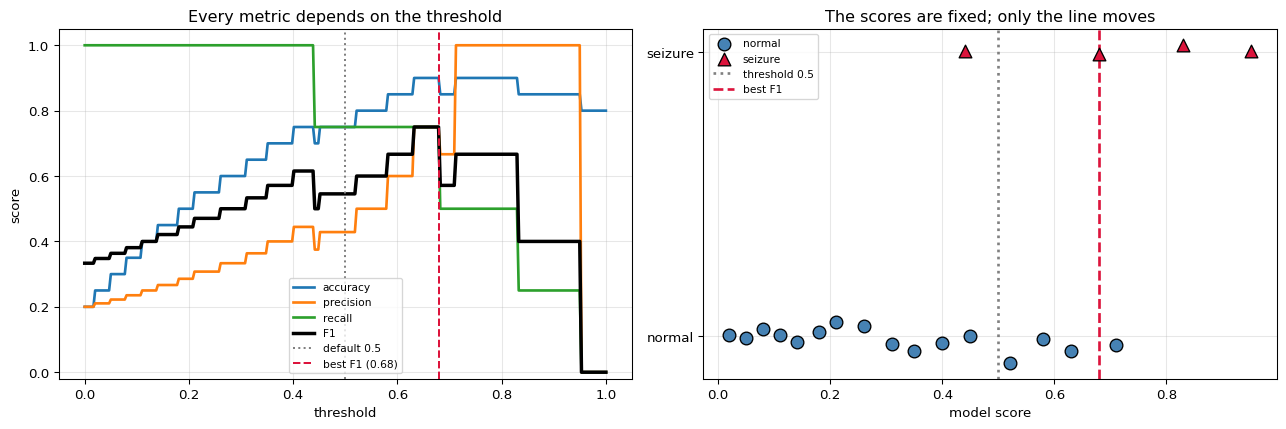

Right panel: one seizure (e16) scored 0.44 and sits among the negatives.
No threshold separates the classes perfectly here - moving the line just
trades one error type for the other.


In [6]:
ths = np.linspace(0, 1.0, 300)
acc_c = [metrics_at(t)[4] for t in ths]
pre_c = [metrics_at(t)[5] for t in ths]
rec_c = [metrics_at(t)[6] for t in ths]
f1_c = [metrics_at(t)[7] for t in ths]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
ax = axes[0]
ax.plot(ths, acc_c, lw=2, label="accuracy")
ax.plot(ths, pre_c, lw=2, label="precision")
ax.plot(ths, rec_c, lw=2, label="recall")
ax.plot(ths, f1_c, lw=2.6, color="k", label="F1")
ax.axvline(0.5, ls=":", color="grey", label="default 0.5")
ax.axvline(best_f1[1], ls="--", color="crimson", label=f"best F1 ({best_f1[1]:.2f})")
ax.set(xlabel="threshold", ylabel="score", ylim=(-.02, 1.05),
       title="Every metric depends on the threshold")
ax.legend(fontsize=8); ax.grid(alpha=.3)

ax = axes[1]
for c, col, mk in [(0, "steelblue", "o"), (1, "crimson", "^")]:
    m = y_true == c
    ax.scatter(scores[m], np.full(m.sum(), c) + np.random.default_rng(0).normal(0, .04, m.sum()),
               s=90, color=col, marker=mk, edgecolor="k", zorder=3,
               label="seizure" if c else "normal")
ax.axvline(0.5, ls=":", color="grey", lw=2, label="threshold 0.5")
ax.axvline(best_f1[1], ls="--", color="crimson", lw=2, label=f"best F1")
ax.set(xlabel="model score", yticks=[0, 1], yticklabels=["normal", "seizure"],
       title="The scores are fixed; only the line moves")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Right panel: one seizure (e16) scored 0.44 and sits among the negatives.")
print("No threshold separates the classes perfectly here - moving the line just")
print("trades one error type for the other.")

---
# 5. ROC and AUC

Rather than pick one threshold, sweep **all** of them and plot the result. The ROC curve
plots:

$$\text{TPR (recall)} = \frac{TP}{TP+FN}
\qquad\text{against}\qquad
\text{FPR} = \frac{FP}{FP+TN}$$

**AUC** is the area under that curve, and it has an interpretation that makes it worth
knowing:

> AUC is the probability that a randomly chosen **positive** scores higher than a randomly
> chosen **negative**.

So AUC = 0.5 is a coin flip and AUC = 1.0 is perfect separation. Crucially it is
**threshold-free** &mdash; it measures the *ranking*, not any particular decision. That
interpretation is verified below by counting pairs directly.

In [7]:
order = np.argsort(-scores)
roc_pts = [(0.0, 0.0)]
tp_r = fp_r = 0
print("building the ROC curve by walking down the sorted scores\n")
print(f"{'rank':>5}  {'id':>5}  {'score':>7}  {'true':>5}  {'TP':>3}  {'FP':>3}  "
      f"{'TPR':>8}  {'FPR':>8}")
print("-" * 62)
for r, i in enumerate(order, 1):
    if y_true[i] == 1:
        tp_r += 1
    else:
        fp_r += 1
    tpr, fpr = tp_r/pos, fp_r/neg
    roc_pts.append((fpr, tpr))
    step = "  <- step UP  (a positive)" if y_true[i] == 1 else "  <- step RIGHT (a negative)"
    print(f"{r:>5}  {ep[i]:>5}  {scores[i]:>7.2f}  {y_true[i]:>5}  {tp_r:>3}  {fp_r:>3}  "
          f"{tpr:>8.4f}  {fpr:>8.4f}{step if r <= 8 else ''}")
print("-" * 62)

roc = np.array(roc_pts)
auc_trap = float(np.trapezoid(roc[:,1], roc[:,0])) if hasattr(np, "trapezoid") \
           else float(np.trapz(roc[:,1], roc[:,0]))
print(f"\nAUC by trapezoidal area under the curve: {auc_trap:.6f}")

wins = ties = 0
for i in np.where(y_true == 1)[0]:
    for j in np.where(y_true == 0)[0]:
        if scores[i] > scores[j]:
            wins += 1
        elif scores[i] == scores[j]:
            ties += 1
total_pairs = pos * neg
auc_pairs = (wins + 0.5*ties) / total_pairs
print(f"\nAUC by counting pairs:")
print(f"   positive-negative pairs      : {pos} x {neg} = {total_pairs}")
print(f"   pairs where positive > negative: {wins}")
print(f"   ties (counted as half)        : {ties}")
print(f"   AUC = ({wins} + 0.5*{ties}) / {total_pairs} = {auc_pairs:.6f}")
print(f"\n   trapezoid vs pair-counting MATCH: "
      f"{np.isclose(auc_trap, auc_pairs)}")
print(f"\nThe two definitions agree exactly, which is the point: AUC really is")
print(f"'how often does the model rank a seizure above a non-seizure'.")

building the ROC curve by walking down the sorted scores

 rank     id    score   true   TP   FP       TPR       FPR
--------------------------------------------------------------
    1    e19     0.95      1    1    0    0.2500    0.0000  <- step UP  (a positive)
    2    e18     0.83      1    2    0    0.5000    0.0000  <- step UP  (a positive)
    3    e15     0.71      0    2    1    0.5000    0.0625  <- step RIGHT (a negative)
    4    e17     0.68      1    3    1    0.7500    0.0625  <- step UP  (a positive)
    5    e14     0.63      0    3    2    0.7500    0.1250  <- step RIGHT (a negative)
    6    e13     0.58      0    3    3    0.7500    0.1875  <- step RIGHT (a negative)
    7    e12     0.52      0    3    4    0.7500    0.2500  <- step RIGHT (a negative)
    8    e11     0.45      0    3    5    0.7500    0.3125  <- step RIGHT (a negative)
    9    e16     0.44      1    4    5    1.0000    0.3125
   10    e10     0.40      0    4    6    1.0000    0.3750
   11    e09

### Why the PR curve is the better one here

ROC has a weakness on imbalanced data, and it comes straight from the FPR formula:

$$\text{FPR} = \frac{FP}{FP+TN}$$

With 16 negatives and 4 positives, going from 0 to 4 false alarms moves FPR by only
$4/16 = 0.25$. With 10 000 negatives it would move it by 0.0004 &mdash; **invisible**. The
enormous $TN$ count in the denominator hides false alarms.

Precision has no $TN$:

$$\text{precision} = \frac{TP}{TP+FP}$$

so 4 false alarms against 4 true detections halves it, whatever the negative count. On
imbalanced problems the **precision-recall curve** is the more honest picture, and its
baseline is the positive rate rather than 0.5.

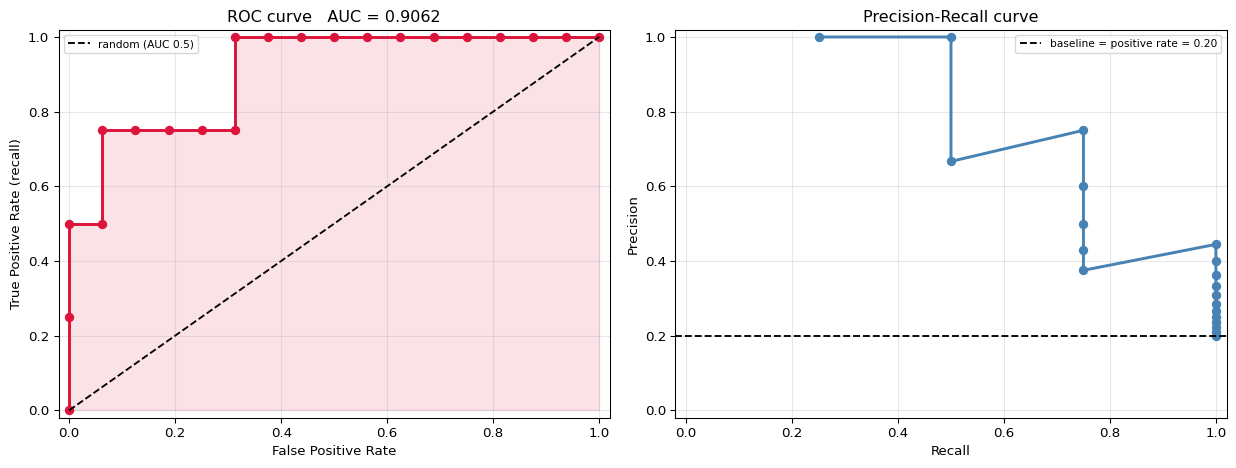

the same model at four operating points

 threshold    recall   precision       FPR           what it means in practice
------------------------------------------------------------------------------
      0.20    1.0000      0.2857    0.6250  catch nearly everything, many alarms
      0.44    1.0000      0.4444    0.3125                catch all 4 seizures
      0.50    0.7500      0.4286    0.2500                         the default
      0.80    0.5000      1.0000    0.0000           only alarm when very sure
------------------------------------------------------------------------------

The ROC and PR curves contain the SAME information - both are just the
score ranking, re-plotted. But PR makes the cost of false alarms visible
at a glance, and ROC does not when negatives vastly outnumber positives.


In [8]:
pr_pts = []
tp_r = fp_r = 0
for i in order:
    if y_true[i] == 1:
        tp_r += 1
    else:
        fp_r += 1
    pr_pts.append((tp_r/pos, tp_r/(tp_r+fp_r)))
pr = np.array(pr_pts)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.plot(roc[:,0], roc[:,1], "o-", lw=2.2, color="crimson")
ax.plot([0,1], [0,1], "k--", lw=1.4, label="random (AUC 0.5)")
ax.fill_between(roc[:,0], roc[:,1], alpha=.12, color="crimson")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate (recall)",
       title=f"ROC curve   AUC = {auc_trap:.4f}", xlim=(-.02,1.02), ylim=(-.02,1.02))
ax.legend(fontsize=8); ax.grid(alpha=.3)

ax = axes[1]
ax.plot(pr[:,0], pr[:,1], "o-", lw=2.2, color="steelblue")
ax.axhline(pos/n, ls="--", color="k", lw=1.4,
           label=f"baseline = positive rate = {pos/n:.2f}")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve",
       xlim=(-.02,1.02), ylim=(-.02,1.02))
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("the same model at four operating points\n")
print(f"{'threshold':>10}  {'recall':>8}  {'precision':>10}  {'FPR':>8}  "
      f"{'what it means in practice':>34}")
print("-" * 78)
for thr, note in [(0.20, "catch nearly everything, many alarms"),
                  (0.44, "catch all 4 seizures"),
                  (0.50, "the default"),
                  (0.80, "only alarm when very sure")]:
    tp, fp, fn, tn, acc, p_, r_, f_ = metrics_at(thr)
    print(f"{thr:>10.2f}  {r_:>8.4f}  {p_:>10.4f}  {fp/max(fp+tn,1):>8.4f}  {note:>34}")
print("-" * 78)
print(f"\nThe ROC and PR curves contain the SAME information - both are just the")
print(f"score ranking, re-plotted. But PR makes the cost of false alarms visible")
print(f"at a glance, and ROC does not when negatives vastly outnumber positives.")

---
# 6. Choosing a Threshold From Costs

Once you accept that the threshold is a decision, it can be made properly &mdash; by stating
what the errors cost.

$$\text{expected cost} = C_{FN}\cdot FN \;+\; C_{FP}\cdot FP$$

For seizure detection a missed event is far worse than a false alarm. If a miss costs 20
and an alarm costs 1, the optimal threshold is well below 0.5 &mdash; and it falls out of
arithmetic instead of habit.

  C_FN    C_FP   best thr   TP   FP   FN     cost   cost at 0.5    saving
--------------------------------------------------------------------------
     1       1      0.632    3    1    1        2             5         3
     5       1      0.401    4    5    0        5             9         4
    20       1      0.401    4    5    0        5            24        19
    50       1      0.401    4    5    0        5            54        49
     1       5      0.712    2    0    2        2            21        19
--------------------------------------------------------------------------

As the cost of a miss rises, the optimal threshold falls - the model is
told to become more willing to alarm. Note the last row: when false
alarms are the expensive error, the threshold goes UP instead.

None of this requires retraining. The model produced a ranking; the
threshold turns that ranking into a policy, and the policy should come
from the costs.


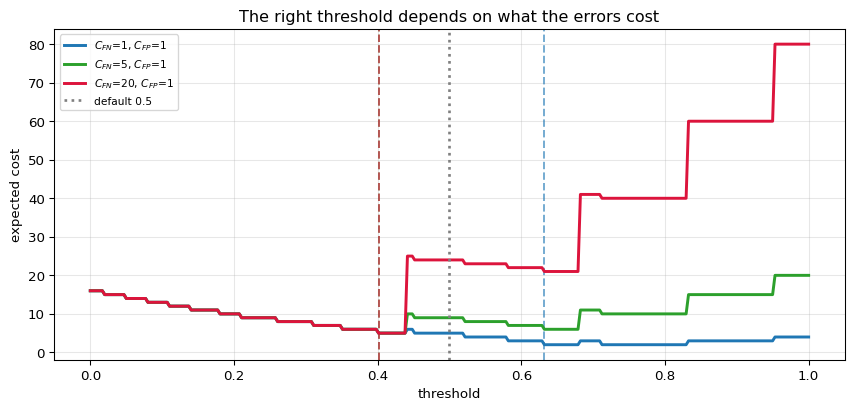

In [9]:
print(f"{'C_FN':>6}  {'C_FP':>6}  {'best thr':>9}  {'TP':>3}  {'FP':>3}  {'FN':>3}  "
      f"{'cost':>7}  {'cost at 0.5':>12}  {'saving':>8}")
print("-" * 74)
for c_fn, c_fp in [(1, 1), (5, 1), (20, 1), (50, 1), (1, 5)]:
    best = None
    for thr in np.linspace(0, 1.001, 400):
        tp, fp, fn, tn = confusion(y_true, scores, thr)
        cost = c_fn*fn + c_fp*fp
        if best is None or cost < best[0]:
            best = (cost, thr, tp, fp, fn)
    tp5, fp5, fn5, tn5 = confusion(y_true, scores, 0.5)
    c5 = c_fn*fn5 + c_fp*fp5
    print(f"{c_fn:>6}  {c_fp:>6}  {best[1]:>9.3f}  {best[2]:>3}  {best[3]:>3}  "
          f"{best[4]:>3}  {best[0]:>7}  {c5:>12}  {c5-best[0]:>8}")
print("-" * 74)

print(f"\nAs the cost of a miss rises, the optimal threshold falls - the model is")
print(f"told to become more willing to alarm. Note the last row: when false")
print(f"alarms are the expensive error, the threshold goes UP instead.")
print(f"\nNone of this requires retraining. The model produced a ranking; the")
print(f"threshold turns that ranking into a policy, and the policy should come")
print(f"from the costs.")

fig, ax = plt.subplots(figsize=(9, 4.4))
for c_fn, col in [(1, "tab:blue"), (5, "tab:green"), (20, "crimson")]:
    costs = [c_fn*confusion(y_true, scores, t)[2] + 1*confusion(y_true, scores, t)[1]
             for t in ths]
    ax.plot(ths, costs, lw=2.2, color=col, label=f"$C_{{FN}}$={c_fn}, $C_{{FP}}$=1")
    bt = ths[int(np.argmin(costs))]
    ax.axvline(bt, ls="--", color=col, alpha=.6)
ax.axvline(0.5, ls=":", color="grey", lw=2, label="default 0.5")
ax.set(xlabel="threshold", ylabel="expected cost",
       title="The right threshold depends on what the errors cost")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# 7. Regression Metrics, Briefly

For continuous targets the same principle applies &mdash; each metric encodes an assumption
about which errors matter.

| Metric | Formula | Character |
|---|---|---|
| MSE | $\frac{1}{n}\sum(y-\hat y)^2$ | punishes large errors hardest; units squared |
| RMSE | $\sqrt{\text{MSE}}$ | same, back in the original units |
| MAE | $\frac{1}{n}\sum\lvert y-\hat y\rvert$ | every error counts linearly; outlier-tolerant |
| $R^2$ | $1 - SS_{res}/SS_{tot}$ | relative to predicting the mean |
| MAPE | $\frac{100}{n}\sum\lvert\frac{y-\hat y}{y}\rvert$ | percentage; **breaks when $y \approx 0$** |

In [10]:
y_r = np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0])
p_a = np.array([2.5, 4.5, 6.5, 8.5, 10.5, 12.5])      # small error everywhere
p_b = np.array([2.0, 4.0, 6.0, 8.0, 10.0, 15.0])      # perfect except one big miss

print(f"two models with the SAME total absolute error\n")
print(f"{'id':>4}  {'y':>7}  {'model A':>9}  {'err A':>8}  {'model B':>9}  {'err B':>8}")
print("-" * 52)
for i in range(len(y_r)):
    print(f"{i:>4}  {y_r[i]:>7.1f}  {p_a[i]:>9.1f}  {y_r[i]-p_a[i]:>8.2f}  "
          f"{p_b[i]:>9.1f}  {y_r[i]-p_b[i]:>8.2f}")
print("-" * 52)
print(f"{'|sum|':>4}  {'':>7}  {'':>9}  {np.abs(y_r-p_a).sum():>8.2f}  {'':>9}  "
      f"{np.abs(y_r-p_b).sum():>8.2f}")

def r2(yv, pv):
    return 1 - ((yv-pv)**2).sum()/((yv-yv.mean())**2).sum()

print(f"\n{'metric':>10}  {'model A':>11}  {'model B':>11}  {'prefers':>9}")
print("-" * 46)
for nm, fn_ in [("MAE", lambda a,b: np.abs(a-b).mean()),
                ("MSE", lambda a,b: ((a-b)**2).mean()),
                ("RMSE", lambda a,b: np.sqrt(((a-b)**2).mean())),
                ("R^2", lambda a,b: r2(a,b))]:
    va, vb = fn_(y_r, p_a), fn_(y_r, p_b)
    if nm == "R^2":
        pref = "A" if va > vb else "B"
    else:
        pref = "A" if va < vb else "B"
    print(f"{nm:>10}  {va:>11.4f}  {vb:>11.4f}  {pref:>9}")
print("-" * 46)
print(f"\nMAE calls them equal ({np.abs(y_r-p_a).mean():.2f} vs "
      f"{np.abs(y_r-p_b).mean():.2f}). MSE strongly prefers A, because")
print(f"one error of 3 costs 9 while six errors of 0.5 cost 1.5 in total.")
print(f"\nNeither is right. If one large miss is much worse than several small")
print(f"ones - a spike detector, say - use MSE. If they are equally bad, use MAE.")

two models with the SAME total absolute error

  id        y    model A     err A    model B     err B
----------------------------------------------------
   0      2.0        2.5     -0.50        2.0      0.00
   1      4.0        4.5     -0.50        4.0      0.00
   2      6.0        6.5     -0.50        6.0      0.00
   3      8.0        8.5     -0.50        8.0      0.00
   4     10.0       10.5     -0.50       10.0      0.00
   5     12.0       12.5     -0.50       15.0     -3.00
----------------------------------------------------
|sum|                          3.00                 3.00

    metric      model A      model B    prefers
----------------------------------------------
       MAE       0.5000       0.5000          B
       MSE       0.2500       1.5000          A
      RMSE       0.5000       1.2247          A
       R^2       0.9786       0.8714          A
----------------------------------------------

MAE calls them equal (0.50 vs 0.50). MSE strongly prefers A, b

---
# 8. Checking Against scikit-learn

In [11]:
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             accuracy_score, mean_squared_error,
                             mean_absolute_error, r2_score)

cm = confusion_matrix(y_true, pred)
print("confusion matrix (sklearn order: [[TN, FP], [FN, TP]])\n")
print(f"   sklearn : {cm.tolist()}")
print(f"   ours    : [[{TN}, {FP}], [{FN}, {TP}]]")
print(f"   MATCH: {cm.tolist() == [[TN, FP], [FN, TP]]}\n")

print(f"{'metric':>14}  {'ours':>12}  {'sklearn':>12}  {'match':>7}")
print("-" * 50)
checks = [
    ("accuracy", (TP+TN)/n, accuracy_score(y_true, pred)),
    ("precision", precision, precision_score(y_true, pred)),
    ("recall", recall, recall_score(y_true, pred)),
    ("F1", f1, f1_score(y_true, pred)),
    ("AUC (trapezoid)", auc_trap, roc_auc_score(y_true, scores)),
    ("AUC (pairs)", auc_pairs, roc_auc_score(y_true, scores)),
]
for nm, a, b in checks:
    print(f"{nm:>14}  {a:>12.8f}  {b:>12.8f}  {str(np.isclose(a,b)):>7}")
print("-" * 50)

fpr_sk, tpr_sk, thr_sk = roc_curve(y_true, scores)
print(f"\nROC curve points")
print(f"   ours    : {len(roc)} points")
print(f"   sklearn : {len(fpr_sk)} points  (it de-duplicates equal thresholds)")
ours_set = {(round(a,10), round(b,10)) for a, b in roc}
sk_set = {(round(a,10), round(b,10)) for a, b in zip(fpr_sk, tpr_sk)}
print(f"   every sklearn point is on our curve: {sk_set <= ours_set}")

print(f"\n\nregression metrics\n")
print(f"{'metric':>10}  {'ours':>12}  {'sklearn':>12}  {'match':>7}")
print("-" * 46)
for nm, a, b in [("MSE", ((y_r-p_a)**2).mean(), mean_squared_error(y_r, p_a)),
                 ("MAE", np.abs(y_r-p_a).mean(), mean_absolute_error(y_r, p_a)),
                 ("R^2", r2(y_r, p_a), r2_score(y_r, p_a))]:
    print(f"{nm:>10}  {a:>12.8f}  {b:>12.8f}  {str(np.isclose(a,b)):>7}")
print("-" * 46)

print(f"\n\nthreshold-free scores on the imbalanced problem\n")
print(f"   ROC AUC          : {roc_auc_score(y_true, scores):.6f}")
print(f"   Average Precision: {average_precision_score(y_true, scores):.6f}  "
      f"(area under PR)")
print(f"   baseline AP      : {pos/n:.6f}  (= the positive rate)")
print(f"\n   ROC AUC looks strong; AP is more modest. On imbalanced data that gap")
print(f"   is normal, and AP is the number to trust.")

confusion matrix (sklearn order: [[TN, FP], [FN, TP]])

   sklearn : [[12, 4], [1, 3]]
   ours    : [[12, 4], [1, 3]]
   MATCH: True

        metric          ours       sklearn    match
--------------------------------------------------
      accuracy    0.75000000    0.75000000     True
     precision    0.42857143    0.42857143     True
        recall    0.75000000    0.75000000     True
            F1    0.54545455    0.54545455     True
AUC (trapezoid)    0.90625000    0.90625000     True
   AUC (pairs)    0.90625000    0.90625000     True
--------------------------------------------------

ROC curve points
   ours    : 21 points
   sklearn : 8 points  (it de-duplicates equal thresholds)
   every sklearn point is on our curve: True


regression metrics

    metric          ours       sklearn    match
----------------------------------------------
       MSE    0.25000000    0.25000000     True
       MAE    0.50000000    0.50000000     True
       R^2    0.97857143    0.97857143   

---
# 9. Summary

| Metric | Formula | Uses TN? | Use it when |
|---|---|---|---|
| Accuracy | $(TP+TN)/n$ | **yes** | classes are balanced and errors cost the same |
| Precision | $TP/(TP+FP)$ | no | false alarms are expensive |
| Recall | $TP/(TP+FN)$ | no | misses are expensive |
| $F_1$ | harmonic mean | no | you need one number and both errors matter |
| Specificity | $TN/(TN+FP)$ | yes | the negative class matters in its own right |
| ROC AUC | area under TPR&ndash;FPR | yes | comparing rankings, roughly balanced data |
| Average Precision | area under PR | no | **imbalanced data** |

**The one idea:** a classifier does not output a class, it outputs a **ranking**. Metrics
that summarise the ranking (AUC, AP) measure the model. Metrics that summarise one
threshold (accuracy, precision, recall, $F_1$) measure the model **plus a policy you
chose** &mdash; and 0.5 is a convention, not a choice.

**The trap to remember:** at 5% prevalence, a model that always says "no" scores 95%
accuracy and zero on everything else. Whenever an accuracy is quoted without the class
balance beside it, the number cannot be interpreted.

**What is deliberately left out:** multi-class averaging (macro, micro, weighted),
Cohen's kappa and Matthews correlation, calibration and reliability diagrams &mdash; a model
can rank perfectly and still have badly wrong probabilities &mdash; and the evaluation of
ranking and detection tasks, where a "correct" detection needs a definition of overlap.